# Vision 2040 Indicator Tracker: The Bahamas

Can The Bahamas monitor its national development plan with open data, and what does that data show?

This notebook walks through the pipeline step by step. `python run_pipeline.py` runs the same steps in one go.

1. Load the indicator framework (20 World Bank indicators mapped to the plan's 4 pillars and 16 goals)
2. Fetch the data from the World Bank API
3. Audit data availability
4. Baseline (2016) against latest value, with a trend test since 2010
5. Compare against Barbados, Jamaica and Trinidad and Tobago

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # run from notebooks/

import pandas as pd
from src import fetch, analysis, charts, report

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
YEARS = lambda d: d.assign(**{c: pd.to_numeric(d[c], errors="coerce").round().astype("Int64")
                                for c in d.columns if c.endswith("_year")})  # show 2016, not 2,016.000

## 1. Indicator framework

In [2]:
indicators, countries = fetch.load_config()
display(countries)
indicators.groupby("pillar").size().rename("indicators").to_frame()

,code,name,role
0,BHS,The Bahamas,focus
1,BRB,Barbados,peer
2,JAM,Jamaica,peer
3,TTO,Trinidad and Tobago,peer
4,CSS,Caribbean small states,aggregate


,indicators
pillar,
Economy,7
Environment,4
Governance,3
Human Capital,6


In [3]:
indicators[['pillar', 'goal', 'short_name', 'code', 'better', 'unit']]

,pillar,goal,short_name,code,better,unit
0,Governance,Goal 2: Well-governed public institutions,Government effectiveness,GOV_WGI_GE.EST,up,index (-2.5 to 2.5)
1,Governance,Goal 1: Open and accountable government,Control of corruption,GOV_WGI_CC.EST,up,index (-2.5 to 2.5)
2,Governance,Goal 3: Rule of law,Intentional homicides,VC.IHR.PSRC.P5,down,per 100k people
3,Human Capital,Goal 5: Health care,Life expectancy at birth,SP.DYN.LE00.IN,up,years
4,Human Capital,Goal 5: Health care,Under-5 mortality,SH.DYN.MORT,down,per 1k live births
5,Human Capital,Goal 5: Health care,Health spending,SH.XPD.CHEX.GD.ZS,none,% of GDP
6,Human Capital,Goal 6: Education,Public education spending,SE.XPD.TOTL.GD.ZS,up,% of GDP
7,Human Capital,Goal 6: Education,Tertiary enrollment,SE.TER.ENRR,up,% gross
8,Human Capital,Goal 7: Social policy,Adolescent fertility,SP.ADO.TFRT,down,births per 1k women 15-19
9,Environment,Goal 11: Natural environment,Renewable energy share,EG.FEC.RNEW.ZS,up,% of final energy use


## 2. Fetch from the World Bank API

Responses are cached in `data/raw/`. Pass `refresh=True` to download again.

In [4]:
df, log = fetch.fetch_all(refresh=False)
print(f"{len(df):,} observations, {df.indicator.nunique()} indicators, years {df.year.min()}–{df.year.max()}")
log[log.status.str.startswith(("not", "request"))]   # anything the API didn't return

GOV_WGI_GE.EST         cached        100 rows
GOV_WGI_CC.EST         cached        100 rows
VC.IHR.PSRC.P5         cached        130 rows
SP.DYN.LE00.IN         cached        130 rows
SH.DYN.MORT            cached        130 rows
SH.XPD.CHEX.GD.ZS      cached        130 rows
SE.XPD.TOTL.GD.ZS      cached        130 rows
SE.TER.ENRR            cached        130 rows
SP.ADO.TFRT            cached        130 rows
EG.FEC.RNEW.ZS         cached        130 rows
EN.GHG.CO2.PC.CE.AR5   cached        130 rows
ER.PTD.TOTL.ZS         cached        130 rows
IT.NET.USER.ZS         cached        130 rows
NY.GDP.PCAP.KD         cached        130 rows
NY.GDP.MKTP.KD.ZG      cached        130 rows
FP.CPI.TOTL.ZG         cached        130 rows
GC.DOD.TOTL.GD.ZS      cached        130 rows
ST.INT.RCPT.XP.ZS      cached        130 rows
SL.UEM.TOTL.ZS         cached        130 rows
SL.UEM.1524.ZS         cached        130 rows
2,140 observations, 20 indicators, years 2000–2025


,indicator,status,rows


In [5]:
df.head()

,indicator,indicator_name,country,country_name,year,value
0,EG.FEC.RNEW.ZS,Renewable energy consumption (% of total final energy co...,BHS,"Bahamas, The",2000,0.000
1,EG.FEC.RNEW.ZS,Renewable energy consumption (% of total final energy co...,BHS,"Bahamas, The",2001,0.400
2,EG.FEC.RNEW.ZS,Renewable energy consumption (% of total final energy co...,BHS,"Bahamas, The",2002,0.400
3,EG.FEC.RNEW.ZS,Renewable energy consumption (% of total final energy co...,BHS,"Bahamas, The",2003,1.500
4,EG.FEC.RNEW.ZS,Renewable energy consumption (% of total final energy co...,BHS,"Bahamas, The",2004,1.600


## 3. Data availability audit

An indicator can only be monitored if it is measured regularly and recently.

In [6]:
audit = analysis.coverage_audit(df, indicators)
YEARS(audit.sort_values("bhs_coverage")[["pillar", "short_name", "bhs_years", "bhs_coverage", "peer_coverage",
                                   "latest_year", "gap"]])

,pillar,short_name,bhs_years,bhs_coverage,peer_coverage,latest_year,gap
7,Human Capital,Tertiary enrollment,0,0.000,0.513,<NA>,No Bahamas data
11,Environment,Protected areas,13,0.500,0.500,2025,OK
6,Human Capital,Public education spending,15,0.577,0.833,2023,OK
16,Economy,Central government debt,20,0.769,0.436,2024,OK
17,Economy,Tourism receipts share of exports,21,0.808,0.641,2020,Out of date
9,Environment,Renewable energy share,23,0.885,0.859,2022,Out of date
2,Governance,Intentional homicides,23,0.885,0.910,2022,Out of date
5,Human Capital,Health spending,24,0.923,0.923,2023,OK
14,Economy,GDP growth,25,0.962,1.000,2024,OK
13,Economy,GDP per capita,25,0.962,1.000,2024,OK


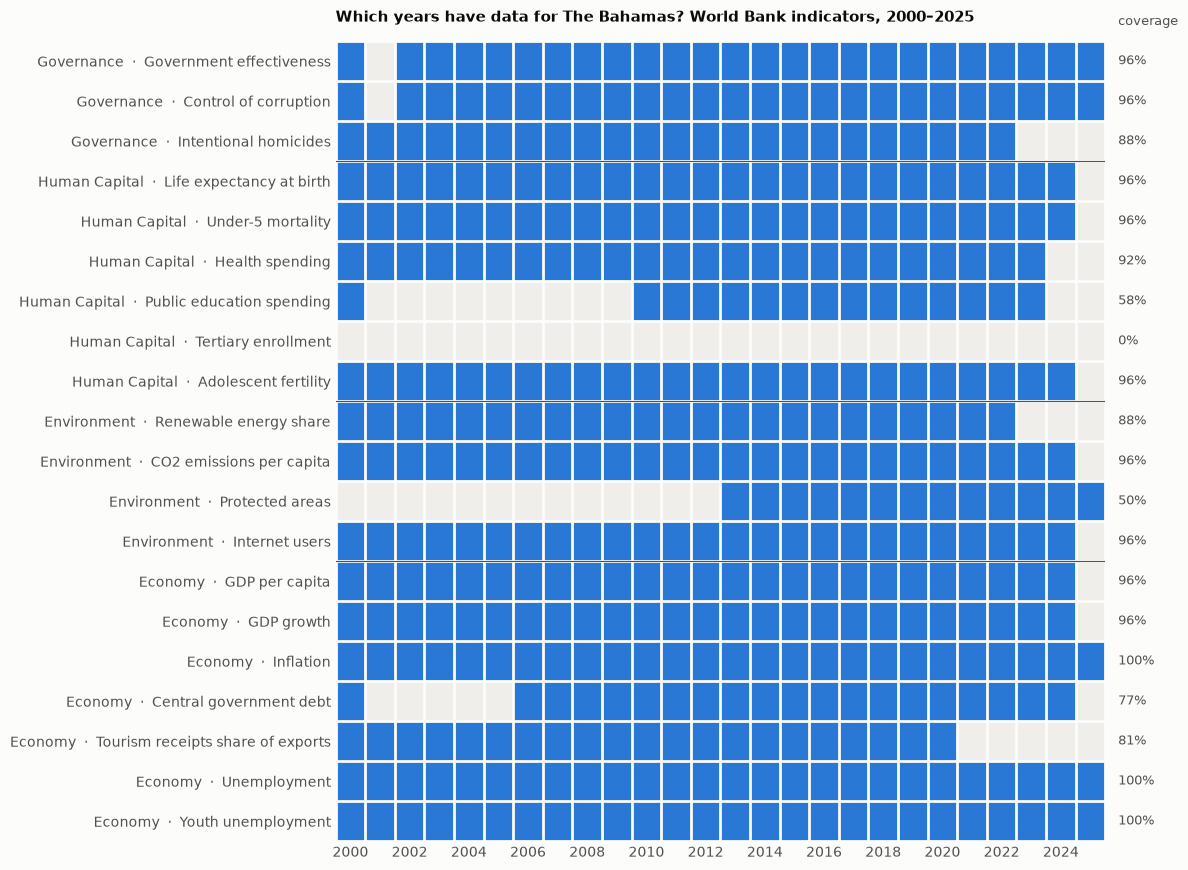

In [7]:
charts.coverage_heatmap(df, indicators, audit);

## 4. Baseline against latest, and trend tests

- **Baseline:** the value nearest to 2016, within ±2 years. Vision 2040 planning began in 2016.
- **Trend:** OLS of value on year from 2010. A trend is *improving* or *worsening* only if p < 0.05
  and the slope points in the indicator's better or worse direction. Annual series can be autocorrelated, so treat
  the p-values as a screening tool.

In [8]:
card = analysis.scorecard(df, indicators)
YEARS(card[["pillar", "short_name", "baseline_year", "baseline", "latest_year", "latest",
      "slope_per_year", "slope_ci_low", "slope_ci_high", "p_value", "status"]])

,pillar,short_name,baseline_year,baseline,latest_year,latest,slope_per_year,slope_ci_low,slope_ci_high,p_value,status
0,Governance,Government effectiveness,2016,0.664,2025,0.649,0,-0.028,-0.009,0.001,Worsening
1,Governance,Control of corruption,2016,1.089,2025,1.044,0,-0.036,-0.007,0.007,Worsening
2,Governance,Intentional homicides,2016,28.604,2022,32.198,0,-1.226,0.451,0.331,No clear trend
3,Human Capital,Life expectancy at birth,2016,74.042,2024,74.710,0,-0.155,0.141,0.920,No clear trend
4,Human Capital,Under-5 mortality,2016,13.800,2024,12.400,0,-0.489,0.261,0.522,No clear trend
5,Human Capital,Health spending,2016,5.655,2023,6.303,0,0.067,0.200,0.001,Context only
6,Human Capital,Public education spending,2016,2.588,2023,2.742,0,0.009,0.101,0.023,Improving
7,Human Capital,Tertiary enrollment,<NA>,NaN,<NA>,NaN,<NA>,NaN,NaN,NaN,Too little data
8,Human Capital,Adolescent fertility,2016,28.989,2024,24.519,-1,-1.236,-0.841,0.000,Improving
9,Environment,Renewable energy share,2016,1.200,2022,1.100,0,-0.043,-0.006,0.013,Worsening


In [9]:
card.status.value_counts()

status
No clear trend     6
Improving          6
Worsening          5
Context only       2
Too little data    1
Name: count, dtype: int64

### A closer look at one trend

Look at the regression behind one result. Change `CODE` to any indicator in the framework.

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -6964.6844    753.185     -9.247      0.000   -8591.843   -5337.526
x1             3.4809      0.373      9.322      0.000       2.674       4.288


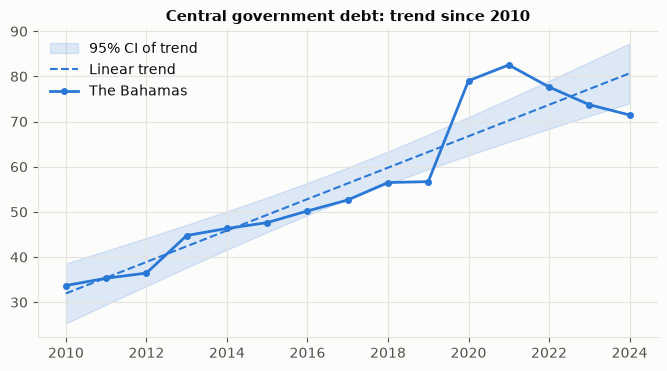

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

CODE = "GC.DOD.TOTL.GD.ZS"   # central government debt, % of GDP
s = df[(df.indicator == CODE) & (df.country == analysis.FOCUS) & (df.year >= analysis.TREND_START)]
if len(s) >= analysis.MIN_TREND_POINTS:
    fit = sm.OLS(s.value.values, sm.add_constant(s.year.values.astype(float))).fit()
    print(fit.summary().tables[1])
    pred = fit.get_prediction(sm.add_constant(s.year.values.astype(float))).summary_frame(alpha=0.05)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.fill_between(s.year, pred.mean_ci_lower, pred.mean_ci_upper, color=charts.FOCUS_COLOR, alpha=0.15,
                    label="95% CI of trend")
    ax.plot(s.year, pred["mean"], color=charts.FOCUS_COLOR, lw=1.5, ls="--", label="Linear trend")
    ax.plot(s.year, s.value, "o-", color=charts.FOCUS_COLOR, lw=2, ms=4, label="The Bahamas")
    name = indicators.set_index("code").at[CODE, "short_name"]
    ax.set(title=f"{name}: trend since {analysis.TREND_START}", xlabel=None)
    ax.legend(frameon=False)
else:
    print("Not enough observations for a trend test.")

## 5. Compared with peers

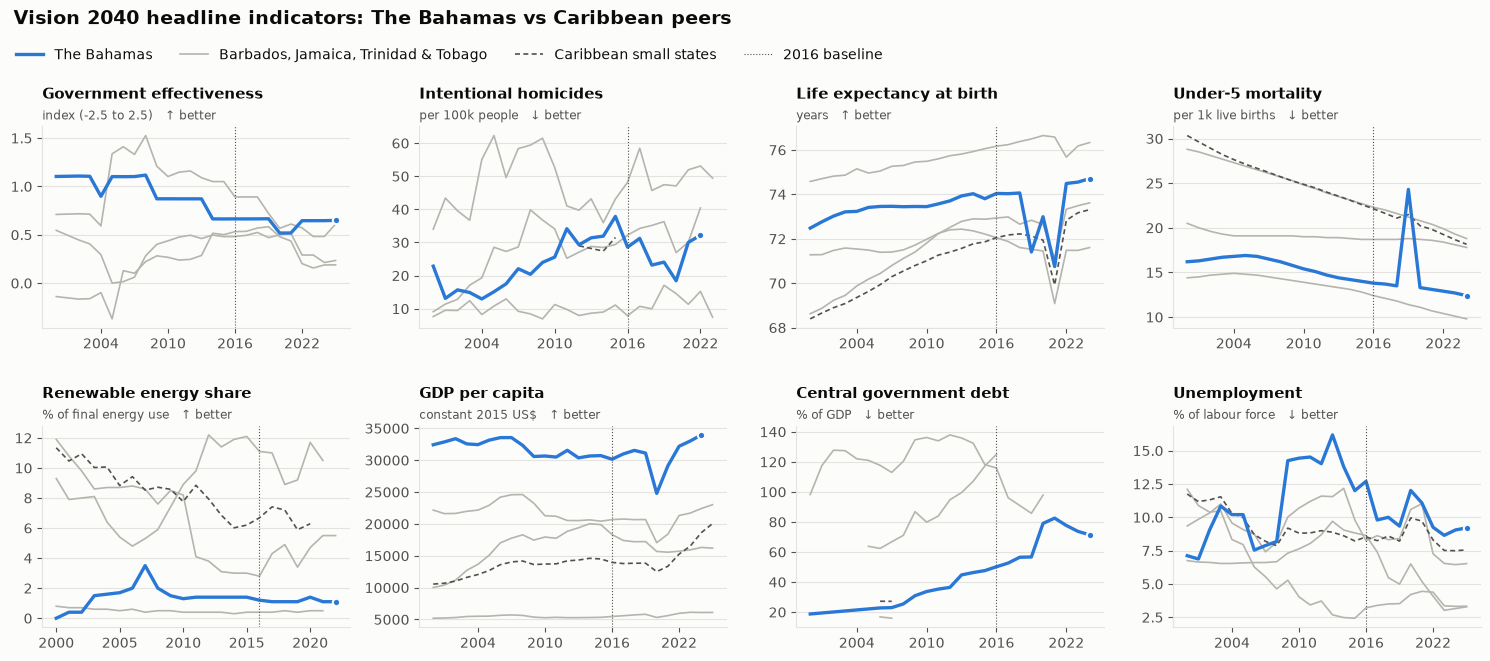

In [11]:
charts.peer_trends(df, indicators);

In [12]:
YEARS(card[["pillar", "short_name", "better", "latest", "latest_year", "peer_rank", "n_ranked",
      "caribbean_small_states_latest"]].dropna(subset=["peer_rank"]).sort_values("peer_rank"))

,pillar,short_name,better,latest,latest_year,peer_rank,n_ranked,caribbean_small_states_latest
0,Governance,Government effectiveness,up,0.649,2025,1.000,4,NaN
8,Human Capital,Adolescent fertility,down,24.519,2024,1.000,4,45.840
11,Environment,Protected areas,up,8.300,2025,1.000,4,6.242
12,Environment,Internet users,up,92.473,2024,1.000,4,NaN
13,Economy,GDP per capita,up,"33,968.203",2024,1.000,4,"20,052.890"
14,Economy,GDP growth,up,3.379,2024,1.000,4,7.975
1,Governance,Control of corruption,up,1.044,2025,2.000,4,NaN
2,Governance,Intentional homicides,down,32.198,2022,2.000,4,31.500
3,Human Capital,Life expectancy at birth,up,74.710,2024,2.000,4,73.313
4,Human Capital,Under-5 mortality,down,12.400,2024,2.000,4,18.154


## 6. Save outputs and update the README

In [13]:
out = fetch.ROOT / "outputs"
audit.to_csv(out / "data_coverage_audit.csv", index=False)
card.to_csv(out / "indicator_scorecard.csv", index=False)
report.update_readme(card, audit)
print(report.findings(card, audit))

- **Data availability.** 19 of 20 indicators have any Bahamas data since 2000. On average The Bahamas has a value for 85% of years, against 87% for Barbados, Jamaica and Trinidad and Tobago.

- **Gaps that would block monitoring** (no data, sparse, or more than 3 years old): Intentional homicides (Out of date, latest 2022); Tertiary enrollment (No Bahamas data); Renewable energy share (Out of date, latest 2022); Tourism receipts share of exports (Out of date, latest 2020).

- **Direction of travel since 2010** (linear trend, 95% confidence): 6 improving, 5 worsening, 6 no clear trend, 1 too little data.

- **Improving:** Public education spending (2.59 in 2016 → 2.74 in 2023); Adolescent fertility (29.0 in 2016 → 24.5 in 2024); Protected areas (1.20 in 2016 → 8.30 in 2025); Internet users (80.0 in 2016 → 92.5 in 2024); Unemployment (12.7 in 2016 → 9.21 in 2025); Youth unemployment (25.8 in 2016 → 19.2 in 2025).

- **Worsening:** Government effectiveness (0.66 in 2016 → 0.65 in 2025); C

## Next steps

- Add national sources where World Bank coverage is thin, such as BNSI labour force surveys and Ministry of Finance debt reports.
- Express crime as a rate: RBPF annual murder counts divided by population give a homicide rate that is more current than the World Bank series.
- Set targets for 2030 and 2040 and report distance to target, not just direction of travel.